# Copper V16-11 — Non-SA models & regime strategies (Standalone)

File chạy **độc lập** với notebook còn lại; không cần đọc checkpoint từ notebook khác. `FULL_MODE` ở đây là FULL trong **ngân sách huấn luyện an toàn hơn**, KHÔNG có nghĩa tái hiện toàn bộ 650 scenarios của paper. Không thể cam kết chắc chắn thời gian GPU nếu Kaggle thay đổi quota/tốc độ. Dữ liệu từ `dataset_9_commodities_daily.csv`.

**Mặc định HORIZON=0:** X[t-21:t] (bao gồm WTI/Gold/Silver ngày t) → Copper(t) (nowcasting). `HORIZON=1` mới là dự báo trước khi có thông tin ngày t. **Residual models** thêm Copper(t−1) để tính ΔCopper và phải so sánh riêng với Paper3.


## 1. Cấu hình và môi trường


In [9]:
from pathlib import Path
import zipfile
from datetime import datetime, timezone
import os, gc, json, time, math, hashlib, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import Ridge
import tensorflow as tf


SEED=42
MODE='FULL_MODE'  # QUICK_MODE | FULL_MODE
MODE_CFG={
 'QUICK_MODE':{'epochs':4,'search_epochs':3,'sa_evals':0,'strategy_seeds':[42],'earlystop':True},
 'FULL_MODE':{'epochs':100,'search_epochs':0,'sa_evals':0,'strategy_seeds':[42],'earlystop':True},
}
CFG=MODE_CFG[MODE]
LOOKBACK=22
HORIZON=0
RATIOS=[.90,.925,.95]
BATCH_SIZE=64
FEATURE_MODES=['paper3','legacy14']
RUN_ADAPTIVE=True
RUN_WALK_FORWARD_CHECK=False
MAX_RUNTIME_MINUTES=180
JOB_START=time.monotonic()
DATASET_CANDIDATES=[
 Path('/kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily/dataset_9_commodities_daily.csv'),
 Path('/kaggle/input/dataset-9-commodities-daily/dataset_9_commodities_daily.csv'),
 Path('data/processed/dataset_9_commodities_daily.csv'),
]
OUT=Path('/kaggle/working/copper_non_sa_v16') if Path('/kaggle/working').exists() else Path('copper_non_sa_v16')
OUT.mkdir(parents=True,exist_ok=True)
tf.keras.utils.set_random_seed(SEED)
for gpu in tf.config.list_physical_devices('GPU'):
 try: tf.config.experimental.set_memory_growth(gpu,True)
 except RuntimeError: pass
print('Standalone non-SA notebook',MODE,'GPU:',tf.config.list_physical_devices('GPU'))


Standalone non-SA notebook FULL_MODE GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Dataset
NOTEBOOK_NAME='Copper V16-11 — Non-SA models & regime strategies '


In [10]:
TARGET = 'Copper'
PAPER3 = ['WTI', 'Gold', 'Silver']
LEGACY14 = ['Aluminium', 'Tin', 'Silver', 'Gold']
CANDIDATES = ['Aluminium', 'Nickel', 'Tin', 'Iron_Ore_62', 'Silver', 'Gold', 'WTI', 'Brent']

DATA_PATH = next((p for p in DATASET_CANDIDATES if p.is_file()), None)
if DATA_PATH is None and Path('/kaggle/input').exists():
    matches = list(Path('/kaggle/input').rglob('dataset_9_commodities_daily.csv'))
    if len(matches) == 1: DATA_PATH = matches[0]
if DATA_PATH is None: raise FileNotFoundError('Không tìm thấy dataset_9_commodities_daily.csv; gắn đúng Kaggle dataset.')
raw = pd.read_csv(DATA_PATH)
if 'Date' not in raw.columns or TARGET not in raw.columns:
    raise KeyError('CSV phải có Date và Copper.')
raw['Date'] = pd.to_datetime(raw['Date'], errors='coerce')
for name in [TARGET]+CANDIDATES:
    if name in raw: raw[name] = pd.to_numeric(raw[name], errors='coerce')
if raw['Date'].isna().any(): raise ValueError('Date có dòng không hợp lệ.')
if raw['Date'].duplicated().any(): raise ValueError('Có ngày trùng lặp; xử lý nguồn dữ liệu trước.')
missing = sorted(set(PAPER3+LEGACY14)-set(raw.columns))
if missing: raise ValueError(f'Thiếu cột yêu cầu: {missing}')
available_candidates = [c for c in CANDIDATES if c in raw]
raw = raw.sort_values('Date').reset_index(drop=True)
quality = pd.DataFrame({'column':raw.columns,'missing':raw.isna().sum().values,'dtype':raw.dtypes.astype(str).values})
quality.to_csv(OUT/'data_quality.csv', index=False)
# Để so sánh các nhánh trên CÙNG ngày, loại những ngày thiếu bất kỳ biến ứng viên hiện có.
# Điều này là quy tắc làm sạch chủ động được ghi nhận, không phải chắc chắn như paper.
data = raw.dropna(subset=[TARGET]+available_candidates).reset_index(drop=True)
assert len(data)>1000 and data['Date'].is_monotonic_increasing
print('Dataset:',DATA_PATH, '| raw:',len(raw),'| clean:',len(data), '|',data.Date.iloc[0].date(),'->',data.Date.iloc[-1].date())
display(quality)


Dataset: /kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily/dataset_9_commodities_daily.csv | raw: 2710 | clean: 2710 | 2016-01-13 -> 2026-11-13


,column,missing,dtype
0,Date,0,datetime64[ns]
1,Copper,0,float64
2,Aluminium,0,float64
3,Nickel,0,float64
4,Tin,0,float64
5,Iron_Ore_62,0,float64
6,Silver,0,float64
7,Gold,0,float64
8,WTI,0,float64
9,Brent,0,float64


## 3. Tách chuỗi không leakage


In [11]:
def choose_features(frame, fit_start, val_start, feature_mode):
    train = frame.iloc[fit_start:val_start]
    if feature_mode == 'paper3':
        features = PAPER3.copy()
    elif feature_mode == 'legacy14':
        features = LEGACY14.copy()  # fixed a-priori; only for reproducing 14-11 setting
    elif feature_mode == 'train_top4':
        score = train[[TARGET]+available_candidates].corr(method='spearman')[TARGET].drop(TARGET)
        features = score.abs().sort_values(ascending=False).head(4).index.tolist()
    else: raise ValueError(feature_mode)
    corr = train[[TARGET]+available_candidates].corr(method='spearman')[TARGET].drop(TARGET)
    return features, corr

def prepare_context(frame, test_ratio, scheme='expanding', feature_mode='paper3', val_fraction=.10):
    n = len(frame)
    test_start = int(n*test_ratio)
    val_start = int(test_start*(1-val_fraction))
    assert LOOKBACK+HORIZON < val_start < test_start < n
    if scheme=='expanding' or scheme=='recency_weighted': fit_start=0
    elif scheme=='rolling_756': fit_start=max(0, val_start-756)
    elif scheme=='rolling_1260': fit_start=max(0, val_start-1260)
    else: raise ValueError(scheme)
    features, corr = choose_features(frame, fit_start, val_start, feature_mode)
    xsc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][features])
    ysc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][[TARGET]])
    x = xsc.transform(frame[features]).astype('float32')
    y = ysc.transform(frame[[TARGET]]).ravel().astype('float32')
    prev = np.r_[np.nan, frame[TARGET].to_numpy()[:-1]]
    prev_scaled = (prev - float(ysc.data_min_[0])) / float(ysc.data_range_[0])

    def windows(start,end, strictly_inside_train=False):
        idx = np.arange(start,end)
        idx = idx[(idx-HORIZON-LOOKBACK+1)>=0]
        if strictly_inside_train:
            idx = idx[(idx-HORIZON-LOOKBACK+1)>=fit_start]
        XX = np.stack([x[t-HORIZON-LOOKBACK+1:t-HORIZON+1] for t in idx]).astype('float32')
        YY = y[idx]
        return {'X':XX,'y':YY,'idx':idx,'prev':prev_scaled[idx].astype('float32'),
                'dates':frame.Date.iloc[idx].to_numpy()}
    train=windows(fit_start,val_start,True)
    val=windows(val_start,test_start)
    test=windows(test_start,n)
    assert max(train['idx'])<min(val['idx'])<min(test['idx'])
    assert np.max(train['idx']-HORIZON) < test_start
    assert xsc.n_samples_seen_ == val_start-fit_start
    return {'train':train,'val':val,'test':test,'x_scaler':xsc,'y_scaler':ysc,
            'features':features,'corr':corr,'fit_start':fit_start,'val_start':val_start,
            'test_start':test_start,'scheme':scheme,'ratio':test_ratio,'feature_mode':feature_mode}

# Independent smoke assertions for alignment, no test labels in input, scaler fit on train only.
ctx0=prepare_context(data,0.90)
assert ctx0['train']['X'].shape[1:] == (LOOKBACK,3)
assert len(set(ctx0['train']['idx']).intersection(ctx0['test']['idx']))==0
for ratio in RATIOS:
    c=prepare_context(data,ratio)
    print(f'{ratio:.3f}: train={len(c["train"]["idx"])} val={len(c["val"]["idx"])} test={len(c["test"]["idx"])} | {str(data.Date.iloc[c["test_start"]].date())}')


0.900: train=2174 val=244 test=271 | 2025-10-29
0.925: train=2234 val=251 test=204 | 2026-01-30
0.950: train=2295 val=258 test=136 | 2026-05-07


## 4. Mô hình


In [12]:
def build_lstm(input_shape, hp=None):
    model = tf.keras.Sequential(name='LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(64, return_sequences=True))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(32))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(16, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model


In [13]:
def build_gru(input_shape, hp=None):
    model = tf.keras.Sequential(name='GRU')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.GRU(64, return_sequences=True))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.GRU(32))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(16, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model


In [14]:
def build_cnn1d_lstm(input_shape, hp=None):
    model = tf.keras.Sequential(name='CNN1D_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.Conv1D(filters=32, kernel_size=3, padding='causal', activation='relu'))
    model.add(tf.keras.layers.MaxPooling1D(pool_size=2))
    model.add(tf.keras.layers.LSTM(48, return_sequences=True))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(24))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(16, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model


In [15]:
def build_cnn_gru(input_shape,hp=None):
    # CNN-GRU strategy from 15-11; simple fixed comparison, no expensive grid search here.
    model=tf.keras.Sequential(name='CNN_GRU')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.Conv1D(32,3,padding='causal',activation='relu'))
    model.add(tf.keras.layers.MaxPooling1D(2))
    model.add(tf.keras.layers.GRU(48,return_sequences=True))
    model.add(tf.keras.layers.GRU(24))
    model.add(tf.keras.layers.Dense(16,activation='relu'))
    model.add(tf.keras.layers.Dropout(.2))
    model.add(tf.keras.layers.Dense(1,activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss='mse')
    return model


## 5. Huấn luyện, đánh giá, caching


In [16]:
def reset_keras(seed=SEED):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(int(seed))

def weights_for_context(ctx):
    n=len(ctx['train']['idx']); age=np.arange(n-1,-1,-1,dtype=float)
    w=np.exp(-np.log(2)*age/252)
    return (w/np.mean(w)).astype('float32')

def fit_predict(builder,ctx,hp=None,seed=SEED,epochs=None,scheme=None,residual=False, search=False, skip_test=False):
    reset_keras(seed)
    tr,va = ctx['train'],ctx['val']
    te = None if skip_test else ctx['test']
    model = builder(tr['X'].shape[1:],hp)
    callbacks=[]
    if CFG['earlystop']:
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=7 if not search else 4,restore_best_weights=True)]
    ytr=tr['y']-tr['prev'] if residual else tr['y']
    yva=va['y']-va['prev'] if residual else va['y']
    weights=weights_for_context(ctx) if scheme=='recency_weighted' else None
    begin=time.perf_counter()
    hist=model.fit(tr['X'],ytr,validation_data=(va['X'],yva),epochs=epochs or CFG['epochs'],
                   batch_size=BATCH_SIZE,shuffle=False,callbacks=callbacks,verbose=0,sample_weight=weights)
    seconds=time.perf_counter()-begin
    pv=model.predict(va['X'],verbose=0).ravel()
    pt=model.predict(te['X'],verbose=0).ravel() if te is not None else None
    if residual:
        pv=pv+va['prev']
        if te is not None: pt=pt+te['prev']
    val_mse=float(mean_squared_error(va['y'],pv))
    ret={'val_pred':pv,'test_pred':pt,'val_mse':val_mse,'seconds':seconds,'epochs_run':len(hist.history['loss']),
         'loss_history':hist.history}
    del model;reset_keras(seed)
    return ret

def ridge_residual_prediction(ctx):
    tr,va,te=ctx['train'],ctx['val'],ctx['test']
    model=Ridge(alpha=1.)
    model.fit(tr['X'].reshape(len(tr['X']),-1),tr['y']-tr['prev'])
    pv=va['prev']+model.predict(va['X'].reshape(len(va['X']),-1))
    pt=te['prev']+model.predict(te['X'].reshape(len(te['X']),-1))
    return {'val_pred':pv,'test_pred':pt,'val_mse':float(mean_squared_error(va['y'],pv)),
            'seconds':0.,'epochs_run':0,'loss_history':None}

def evaluate_predictions(ctx,pred,model,seed,branch,scheme):
    true=ctx['test']['y'];ysc=ctx['y_scaler']
    true_raw=ysc.inverse_transform(true.reshape(-1,1)).ravel()
    pred_raw=ysc.inverse_transform(np.asarray(pred['test_pred']).reshape(-1,1)).ravel()
    persistence_scaled=ctx['test']['prev']
    naive_mae=float(mean_absolute_error(true,persistence_scaled))
    row={'branch':branch,'feature_mode':ctx['feature_mode'],'scheme':scheme,'ratio':ctx['ratio'],
         'horizon':HORIZON,'model':model,'seed':seed,'features':','.join(ctx['features']),
         'n_test':len(true),'train_start':str(data.Date.iloc[ctx['fit_start']].date()),
         'test_start':str(data.Date.iloc[ctx['test_start']].date()),
         'val_mse_scaled':pred['val_mse'],'MSE_scaled':float(mean_squared_error(true,pred['test_pred'])),
         'RMSE_raw':float(mean_squared_error(true_raw,pred_raw)**.5),
         'MAE_raw':float(mean_absolute_error(true_raw,pred_raw)),
         'R2_raw':float(r2_score(true_raw,pred_raw)),
         'Relative_MAE_vs_test_persistence':float(mean_absolute_error(true,pred['test_pred'])/naive_mae) if naive_mae>0 else np.nan,
         'MASE':float(mean_absolute_error(true_raw,pred_raw)/np.mean(np.abs(np.diff(data[TARGET].iloc[ctx['fit_start']:ctx['val_start']].to_numpy())))),
         'epochs_run':pred['epochs_run'],'train_seconds':pred['seconds']}
    preds=pd.DataFrame({'Date':ctx['test']['dates'],'ratio':ctx['ratio'],'branch':branch,'scheme':scheme,'feature_mode':ctx['feature_mode'],
                         'model':model,'seed':seed,'actual_raw':true_raw,'pred_raw':pred_raw})
    return row,preds

# Resumption within persistent output directory; no notebook cross-dependency.
result_file=OUT/'results_v16.csv'; pred_file=OUT/'predictions_v16.csv'
RESULT_ROWS = pd.read_csv(result_file).to_dict('records') if result_file.exists() else []
PREDICTIONS = [pd.read_csv(pred_file)] if pred_file.exists() else []

def has_result(ctx,model,seed,branch,scheme):
    return any(str(r.get('model'))==str(model) and str(r.get('branch'))==str(branch)
               and str(r.get('scheme'))==str(scheme)
               and str(r.get('feature_mode'))==str(ctx['feature_mode'])
               and abs(float(r.get('ratio',-1))-float(ctx['ratio']))<1e-6
               and (pd.isna(r.get('seed')) if seed is None else str(r.get('seed'))==str(seed)) for r in RESULT_ROWS)

def within_budget():
    return (time.monotonic()-JOB_START)/60.0 < MAX_RUNTIME_MINUTES

def record_result(ctx, pred, model, seed, branch, scheme):
    row,frame=evaluate_predictions(ctx,pred,model,seed,branch,scheme)
    RESULT_ROWS.append(row);PREDICTIONS.append(frame)
    pd.DataFrame(RESULT_ROWS).to_csv(OUT/'results_v16.csv',index=False)
    pd.concat(PREDICTIONS,ignore_index=True).to_csv(OUT/'predictions_v16.csv',index=False)
    print(f'[{branch}/{scheme}/{ctx["ratio"]}] {model}, seed={seed}: raw_RMSE={row["RMSE_raw"]:.5f}, MSE_scaled={row["MSE_scaled"]:.6f}')


## 6. Mô hình không SA và Naive Persistence


In [17]:
for feature_mode in FEATURE_MODES:
  for ratio in RATIOS:
    ctx=prepare_context(data,ratio,'expanding',feature_mode)
    naive={'test_pred':ctx['test']['prev'],
           'val_mse':float(mean_squared_error(ctx['val']['y'],ctx['val']['prev'])),
           'seconds':0.,'epochs_run':0}
    if not has_result(ctx,'naive_persistence',SEED,'A_fixed_models','expanding'):
        record_result(ctx,naive,'naive_persistence',SEED,'A_fixed_models','expanding')
    for name,builder in [('lstm',build_lstm),('gru',build_gru),
                         ('cnn1d_lstm',build_cnn1d_lstm),('cnn_gru',build_cnn_gru)]:
        if has_result(ctx,name,SEED,'A_fixed_models','expanding'):
            continue
        if not within_budget():
            print('Reached time budget; outputs saved. Re-run to resume.');break
        p=fit_predict(builder,ctx)
        record_result(ctx,p,name,SEED,'A_fixed_models','expanding')


[A_fixed_models/expanding/0.9] naive_persistence, seed=42: raw_RMSE=0.10103, MSE_scaled=0.001021
[A_fixed_models/expanding/0.9] lstm, seed=42: raw_RMSE=1.24927, MSE_scaled=0.156046
[A_fixed_models/expanding/0.9] gru, seed=42: raw_RMSE=0.55716, MSE_scaled=0.031038
[A_fixed_models/expanding/0.9] cnn1d_lstm, seed=42: raw_RMSE=0.82326, MSE_scaled=0.067767
[A_fixed_models/expanding/0.9] cnn_gru, seed=42: raw_RMSE=0.62836, MSE_scaled=0.039478
[A_fixed_models/expanding/0.925] naive_persistence, seed=42: raw_RMSE=0.09840, MSE_scaled=0.000968
[A_fixed_models/expanding/0.925] lstm, seed=42: raw_RMSE=1.51438, MSE_scaled=0.229302
[A_fixed_models/expanding/0.925] gru, seed=42: raw_RMSE=0.55624, MSE_scaled=0.030935
[A_fixed_models/expanding/0.925] cnn1d_lstm, seed=42: raw_RMSE=1.02382, MSE_scaled=0.104806
[A_fixed_models/expanding/0.925] cnn_gru, seed=42: raw_RMSE=0.60931, MSE_scaled=0.037120
[A_fixed_models/expanding/0.95] naive_persistence, seed=42: raw_RMSE=0.09661, MSE_scaled=0.000870
[A_fixed_m

## 7. Chiến lược không SA: rolling / expanding / recency / residual

Chạy trên 90/10 để hạn chế GPU; chỉ 1 seed trong FULL mặc định. Các kiến trúc được xây dựng độc lập với SA. Naive Persistence cho phép so sánh Residual-GRU công bằng theo cùng test dates.


In [18]:
if RUN_ADAPTIVE:
  ratio=.90
  for scheme in ['expanding','rolling_756','recency_weighted']:
    ctx=prepare_context(data,ratio,scheme,'paper3')
    for seed in CFG['strategy_seeds']:
      for name,builder,residual,branch in [
          ('gru',build_gru,False,'B_adaptation'),
          ('cnn_gru',build_cnn_gru,False,'B_adaptation'),
          ('residual_gru',build_gru,True,'B_residual_extension')]:
        if has_result(ctx,name,seed,branch,scheme):continue
        if not within_budget():
            print('Reached time budget; outputs saved; re-run to resume.');break
        p=fit_predict(builder,ctx,seed=seed,scheme=scheme,residual=residual)
        record_result(ctx,p,name,seed,branch,scheme)
    if not has_result(ctx,'ridge_delta',None,'B_residual_extension',scheme):
        p=ridge_residual_prediction(ctx)
        record_result(ctx,p,'ridge_delta',None,'B_residual_extension',scheme)


[B_adaptation/expanding/0.9] gru, seed=42: raw_RMSE=0.55716, MSE_scaled=0.031038
[B_adaptation/expanding/0.9] cnn_gru, seed=42: raw_RMSE=0.62836, MSE_scaled=0.039478
[B_residual_extension/expanding/0.9] residual_gru, seed=42: raw_RMSE=0.10107, MSE_scaled=0.001021
[B_residual_extension/expanding/0.9] ridge_delta, seed=None: raw_RMSE=0.09420, MSE_scaled=0.000887
[B_adaptation/rolling_756/0.9] gru, seed=42: raw_RMSE=0.50022, MSE_scaled=0.069717
[B_adaptation/rolling_756/0.9] cnn_gru, seed=42: raw_RMSE=0.54854, MSE_scaled=0.083834
[B_residual_extension/rolling_756/0.9] residual_gru, seed=42: raw_RMSE=0.10425, MSE_scaled=0.003028
[B_residual_extension/rolling_756/0.9] ridge_delta, seed=None: raw_RMSE=0.11398, MSE_scaled=0.003620
[B_adaptation/recency_weighted/0.9] gru, seed=42: raw_RMSE=0.71348, MSE_scaled=0.050898
[B_adaptation/recency_weighted/0.9] cnn_gru, seed=42: raw_RMSE=0.56372, MSE_scaled=0.031774
[B_residual_extension/recency_weighted/0.9] residual_gru, seed=42: raw_RMSE=0.10097, M

## 8. Đánh giá và trực quan hóa các chiến lược


In [19]:
if not RESULT_ROWS:
    raise RuntimeError('No results yet; run training cells.')
results=pd.DataFrame(RESULT_ROWS)
predictions=pd.concat(PREDICTIONS,ignore_index=True)
results.to_csv(OUT/'results_v16.csv',index=False)
predictions.to_csv(OUT/'predictions_v16.csv',index=False)
summary=results.groupby(['branch','feature_mode','scheme','model','ratio'],dropna=False)[['MSE_scaled','RMSE_raw','MAE_raw','Relative_MAE_vs_test_persistence']].mean().reset_index()
summary.to_csv(OUT/'summary_v16.csv',index=False)
display(summary.sort_values(['ratio','RMSE_raw']).head(30))


,branch,feature_mode,scheme,model,ratio,MSE_scaled,RMSE_raw,MAE_raw,Relative_MAE_vs_test_persistence
37,B_residual_extension,paper3,expanding,ridge_delta,0.900,0.000887,0.094198,0.072272,0.937662
39,B_residual_extension,paper3,recency_weighted,ridge_delta,0.900,0.000887,0.094198,0.072272,0.937662
38,B_residual_extension,paper3,recency_weighted,residual_gru,0.900,0.001019,0.100973,0.076974,0.998664
12,A_fixed_models,legacy14,expanding,naive_persistence,0.900,0.001021,0.101033,0.077077,1.000000
27,A_fixed_models,paper3,expanding,naive_persistence,0.900,0.001021,0.101033,0.077077,1.000000
36,B_residual_extension,paper3,expanding,residual_gru,0.900,0.001021,0.101072,0.077122,1.000590
40,B_residual_extension,paper3,rolling_756,residual_gru,0.900,0.003028,0.104253,0.080466,1.043973
41,B_residual_extension,paper3,rolling_756,ridge_delta,0.900,0.003620,0.113982,0.090624,1.175765
35,B_adaptation,paper3,rolling_756,gru,0.900,0.069717,0.500222,0.453618,5.885271
3,A_fixed_models,legacy14,expanding,cnn_gru,0.900,0.026616,0.515945,0.450254,5.841630


## 9. Residual-GRU Rolling 756 vs Persistence (same test days)


KẾT QUẢ KIỂM ĐỊNH (cùng ngày test):


,Giá trị
feature_mode,paper3
ratio,0.9
seed,42
n_test,271
test_start,2025-10-29
test_end,2026-11-13
naive_MSE_raw,0.010208
residual_gru_MSE_raw,0.010869
naive_RMSE_raw,0.101033
residual_gru_RMSE_raw,0.104253


Residual-GRU Rolling 756 so với Naive theo MAE: CHƯA THẮNG
Theo RMSE: CHƯA THẮNG


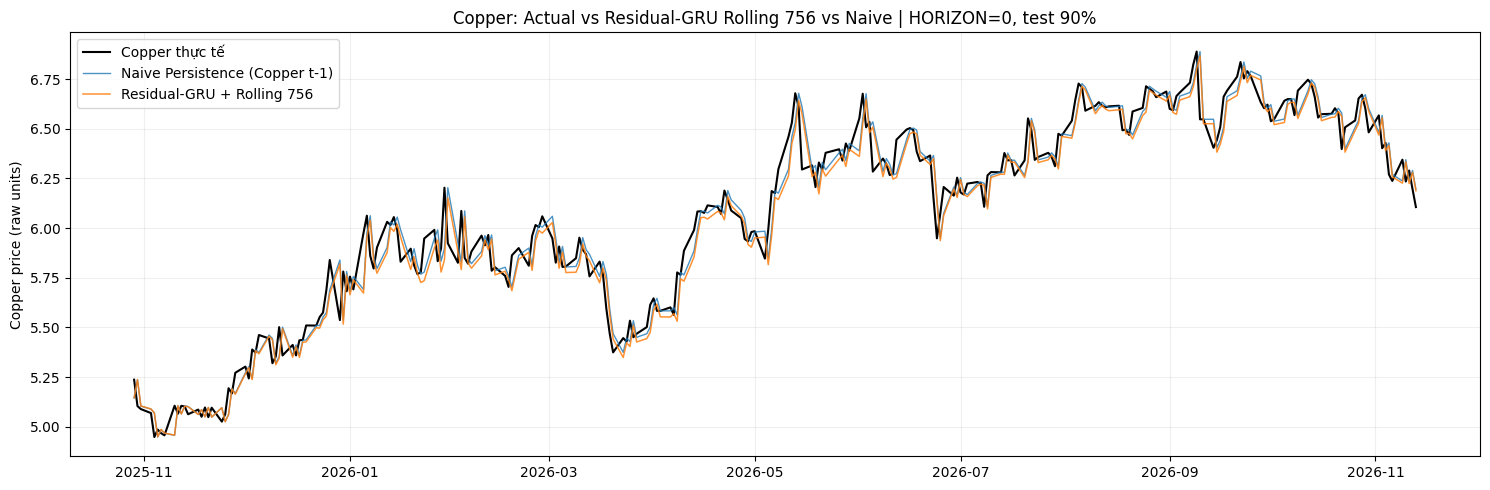

In [20]:
# Explicit paired evaluation: Rolling-756 Residual-GRU vs same-date Naive Persistence
import json

PRIMARY_RATIO = 0.90
REFERENCE_SEED = 42

def paired_comparison(pred_df, ratio=PRIMARY_RATIO, feature_mode='paper3', seed=REFERENCE_SEED):
    base = pred_df[(np.isclose(pred_df['ratio'], ratio)) &
                   (pred_df['feature_mode'] == feature_mode) &
                   (pred_df['branch'] == 'A_fixed_models') &
                   (pred_df['scheme'] == 'expanding') &
                   (pred_df['model'] == 'naive_persistence')][['Date','actual_raw','pred_raw']].copy()
    base['Date'] = pd.to_datetime(base['Date'])
    base = base.rename(columns={'pred_raw':'naive_pred'})
    target = pred_df[(np.isclose(pred_df['ratio'], ratio)) &
                     (pred_df['feature_mode'] == feature_mode) &
                     (pred_df['branch'] == 'B_residual_extension') &
                     (pred_df['scheme'] == 'rolling_756') &
                     (pred_df['model'] == 'residual_gru') &
                     (pred_df['seed'] == seed)][['Date','actual_raw','pred_raw']].copy()
    target['Date'] = pd.to_datetime(target['Date'])
    target = target.rename(columns={'actual_raw':'actual_residual','pred_raw':'residual_pred'})
    if base.empty or target.empty:
        raise RuntimeError('Thiếu kết quả Naive Persistence hoặc Residual-GRU rolling_756. Cần bật RUN_ADAPTIVE=True và strategy_seeds chứa 42.')
    assert not base.Date.duplicated().any() and not target.Date.duplicated().any(), 'Ngày test trùng lặp'
    paired=base.merge(target,on='Date',how='inner',validate='one_to_one').sort_values('Date')
    if len(paired)!=len(base) or len(paired)!=len(target):
        raise AssertionError('Hai mô hình không dùng cùng toàn bộ ngày test')
    if not np.allclose(paired.actual_raw,paired.actual_residual,rtol=1e-6,atol=1e-6):
        raise AssertionError('Nhãn thật giữa hai mô hình khác nhau')
    a=paired.actual_raw.to_numpy()
    naive=paired.naive_pred.to_numpy()
    residual=paired.residual_pred.to_numpy()
    err_n=np.abs(a-naive); err_r=np.abs(a-residual)
    metrics={
      'feature_mode':feature_mode,'ratio':ratio,'seed':seed,
      'n_test':len(paired),'test_start':paired.Date.min().strftime('%Y-%m-%d'),
      'test_end':paired.Date.max().strftime('%Y-%m-%d'),
      'naive_MSE_raw':float(np.mean((a-naive)**2)),
      'residual_gru_MSE_raw':float(np.mean((a-residual)**2)),
      'naive_RMSE_raw':float(np.mean((a-naive)**2)**.5),
      'residual_gru_RMSE_raw':float(np.mean((a-residual)**2)**.5),
      'naive_MAE_raw':float(err_n.mean()),
      'residual_gru_MAE_raw':float(err_r.mean()),
      'MAE_improvement_pct':float(100*(err_n.mean()-err_r.mean())/err_n.mean()) if err_n.mean()>0 else float('nan'),
      'relative_MAE':float(err_r.mean()/err_n.mean()) if err_n.mean()>0 else float('nan'),
      'percent_days_residual_better':float(100*np.mean(err_r<err_n)),
      'wins_by_MAE':bool(err_r.mean()<err_n.mean()),
      'wins_by_RMSE':bool(np.mean((a-residual)**2)<np.mean((a-naive)**2))
    }
    paired['naive_abs_error']=err_n
    paired['residual_abs_error']=err_r
    paired['naive_error']=a-naive
    paired['residual_error']=a-residual
    return metrics,paired

paired_metrics,paired=paired_comparison(predictions)
pd.DataFrame([paired_metrics]).to_csv(OUT/'residual_rolling756_vs_naive.csv',index=False)
paired.to_csv(OUT/'residual_rolling756_paired_daily.csv',index=False)
(OUT/'residual_rolling756_vs_naive.json').write_text(json.dumps(paired_metrics,indent=2),encoding='utf-8')
print('KẾT QUẢ KIỂM ĐỊNH (cùng ngày test):')
display(pd.DataFrame([paired_metrics]).T.rename(columns={0:'Giá trị'}))
print('Residual-GRU Rolling 756 so với Naive theo MAE:', 'THẮNG' if paired_metrics['wins_by_MAE'] else 'CHƯA THẮNG')
print('Theo RMSE:', 'THẮNG' if paired_metrics['wins_by_RMSE'] else 'CHƯA THẮNG')

fig,ax=plt.subplots(figsize=(15,5))
ax.plot(paired.Date,paired.actual_raw,color='black',linewidth=1.5,label='Copper thực tế')
ax.plot(paired.Date,paired.naive_pred,linewidth=1,alpha=.8,label='Naive Persistence (Copper t-1)')
ax.plot(paired.Date,paired.residual_pred,linewidth=1.1,alpha=.85,label='Residual-GRU + Rolling 756')
ax.set(title=f'Copper: Actual vs Residual-GRU Rolling 756 vs Naive | {HORIZON=}, test {PRIMARY_RATIO:.0%}',ylabel='Copper price (raw units)')
ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(OUT/'actual_vs_residual_rolling756_vs_naive.png',dpi=180,bbox_inches='tight');plt.show()


## 10. Top 5, Rolling vs Expanding, Error over time


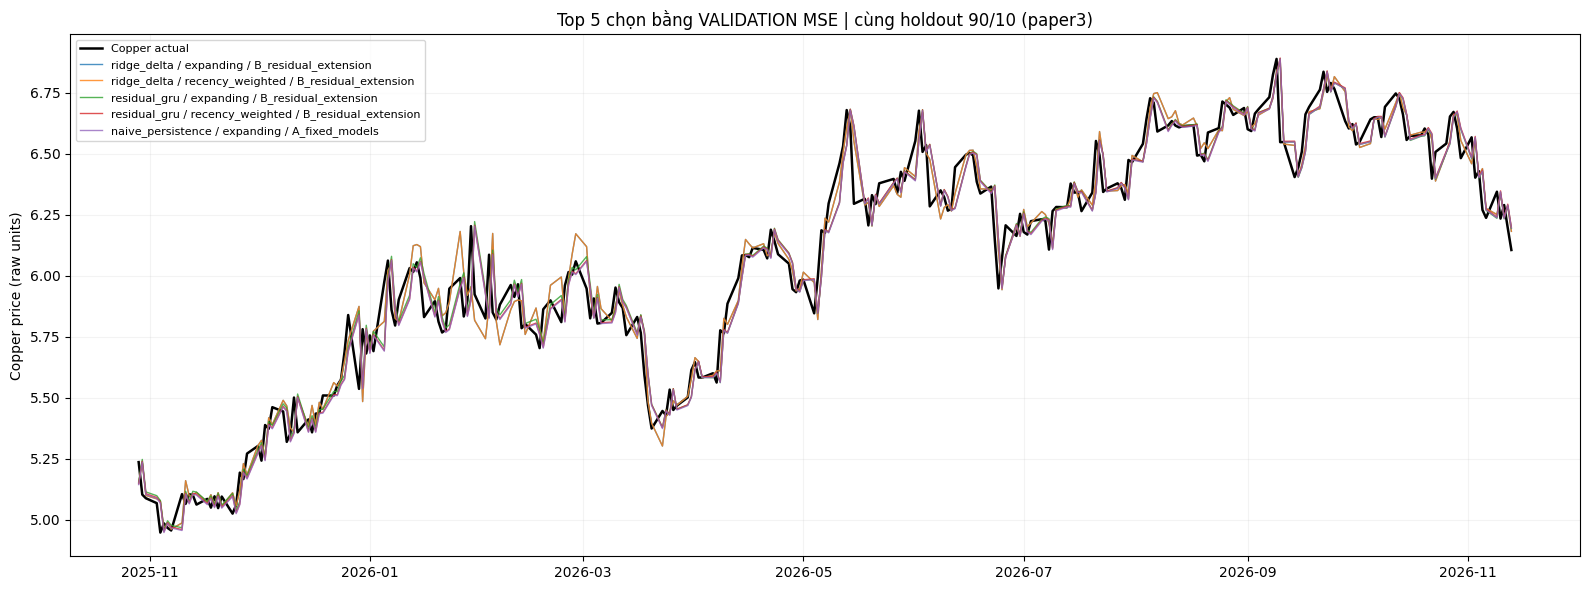

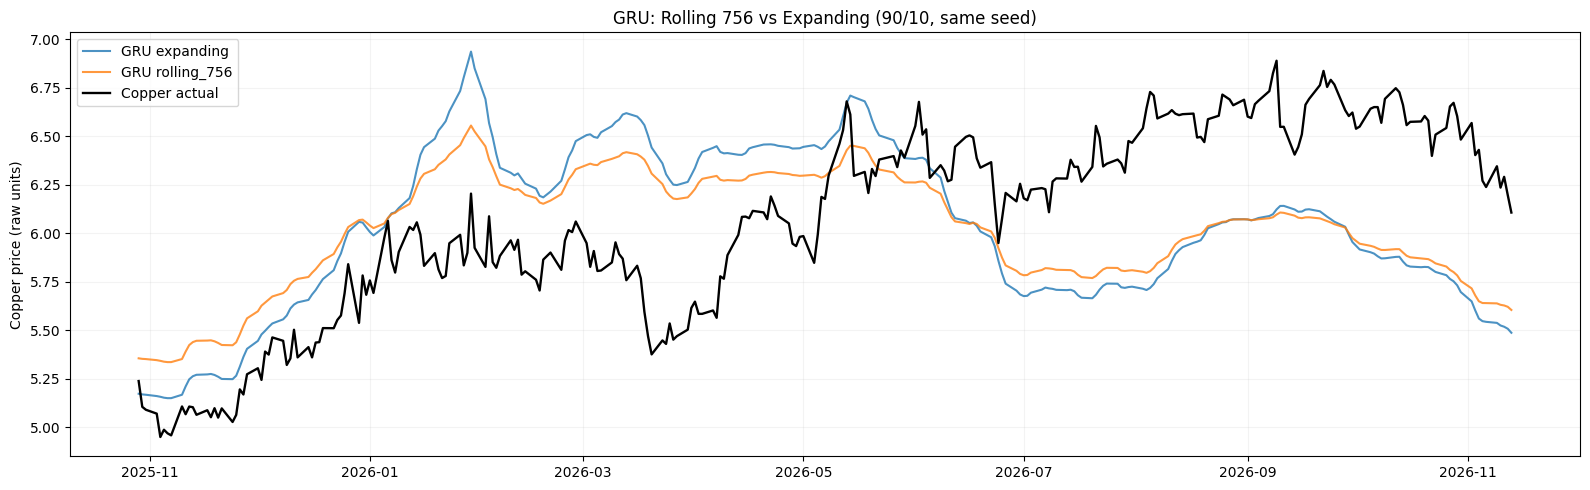

,model,scheme,RMSE_raw,MAE_raw,n_test
0,gru,expanding,0.557161,0.492931,271
1,gru,rolling_756,0.500222,0.453618,271


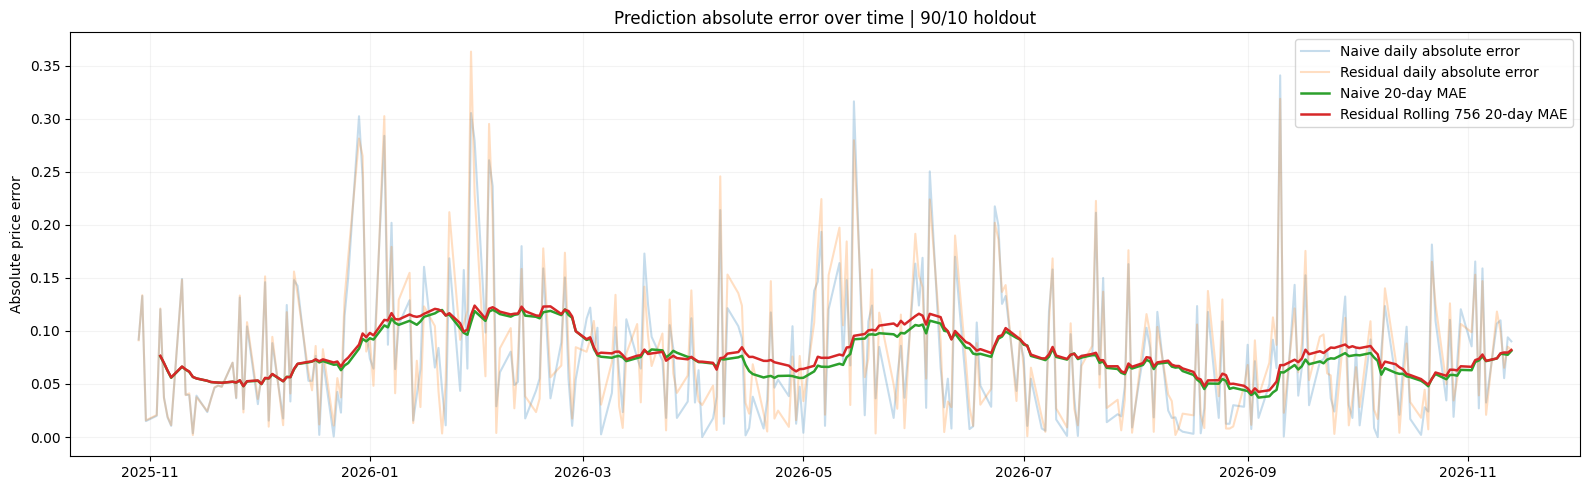

In [21]:
# Choose Top 5 strictly by validation loss, not by held-out test results
selection=results[(np.isclose(results['ratio'],PRIMARY_RATIO)) &
                  (results['feature_mode']=='paper3')].copy()
ranking=(selection.groupby(['branch','scheme','model'],as_index=False)
         .agg(val_mse_scaled=('val_mse_scaled','mean'),n_seeds=('seed','nunique'))
         .sort_values('val_mse_scaled').reset_index(drop=True))
ranking['rank']=np.arange(1,len(ranking)+1)
ranking.to_csv(OUT/'validation_ranked_candidates.csv',index=False)
top5=ranking.head(5)
if len(top5)<5:
    print('WARN: ít hơn 5 cấu hình để vẽ; số lựa chọn hiện có:',len(top5))
selected=[]
for row in top5.itertuples(index=False):
    subset=predictions[(np.isclose(predictions['ratio'],PRIMARY_RATIO)) &
                       (predictions['feature_mode']=='paper3') &
                       (predictions['branch']==row.branch) &
                       (predictions['scheme']==row.scheme) &
                       (predictions['model']==row.model)].copy()
    if subset.empty: continue
    # Average across independent seeds only to visualize candidate mean, not as production ensemble claim.
    avg=(subset.groupby('Date',as_index=False)
         .agg(actual_raw=('actual_raw','first'),pred_raw=('pred_raw','mean')))
    avg['model_label']=f'{row.model} / {row.scheme} / {row.branch}'
    selected.append(avg)

fig,ax=plt.subplots(figsize=(16,6))
if selected:
    ref=selected[0].sort_values('Date')
    ax.plot(pd.to_datetime(ref.Date),ref.actual_raw,label='Copper actual',color='black',linewidth=1.8)
    for d in selected:
        d=d.sort_values('Date')
        ax.plot(pd.to_datetime(d.Date),d.pred_raw,label=d.model_label.iloc[0],alpha=.8,linewidth=1.0)
    ax.legend(fontsize=8)
    ax.set(title='Top 5 chọn bằng VALIDATION MSE | cùng holdout 90/10 (paper3)',ylabel='Copper price (raw units)')
    ax.grid(alpha=.15)
    fig.tight_layout();fig.savefig(OUT/'top5_validation_selected_vs_actual.png',dpi=180,bbox_inches='tight')
plt.show()

# Rolling 756 vs expanding GRU: same architecture, seed, dates, features, horizon
compare=predictions[(np.isclose(predictions.ratio,PRIMARY_RATIO)) &
                    (predictions.feature_mode=='paper3') &
                    (predictions.branch=='B_adaptation') &
                    (predictions.model=='gru') &
                    (predictions.seed==REFERENCE_SEED) &
                    (predictions.scheme.isin(['expanding','rolling_756']))].copy()
fig,ax=plt.subplots(figsize=(16,5))
for scheme,group in compare.groupby('scheme'):
    d=group.sort_values('Date')
    ax.plot(pd.to_datetime(d.Date),d.pred_raw,label=f'GRU {scheme}',alpha=.8)
if not compare.empty:
    d=compare[compare.scheme=='expanding'].sort_values('Date')
    ax.plot(pd.to_datetime(d.Date),d.actual_raw,label='Copper actual',color='black',linewidth=1.7)
ax.set(title='GRU: Rolling 756 vs Expanding (90/10, same seed)',ylabel='Copper price (raw units)')
ax.grid(alpha=.15);ax.legend();fig.tight_layout()
fig.savefig(OUT/'rolling756_vs_expanding_gru.png',dpi=180,bbox_inches='tight');plt.show()

# Quantitative comparison for rolling and expanding GRU, on identical test dates
exp=compare[compare.scheme=='expanding'][['Date','actual_raw','pred_raw']].rename(columns={'pred_raw':'expanding_pred'})
rol=compare[compare.scheme=='rolling_756'][['Date','actual_raw','pred_raw']].rename(columns={'pred_raw':'rolling_pred','actual_raw':'actual_rolling'})
comparison=exp.merge(rol,on='Date',validate='one_to_one',how='inner')
if len(exp)!=len(rol) or len(comparison)!=len(exp):
    raise AssertionError('GRU expanding và rolling không khớp tập ngày test')
if not np.allclose(comparison.actual_raw,comparison.actual_rolling):
    raise AssertionError('Nhãn giữa hai chiến lược GRU không nhất quán')
comprow=[]
for scheme,col in [('expanding','expanding_pred'),('rolling_756','rolling_pred')]:
    yt=comparison.actual_raw.to_numpy();yp=comparison[col].to_numpy()
    comprow.append({'model':'gru','scheme':scheme,'RMSE_raw':float(np.mean((yt-yp)**2)**.5),
                    'MAE_raw':float(np.mean(np.abs(yt-yp))),'n_test':len(comparison)})
pd.DataFrame(comprow).to_csv(OUT/'rolling_vs_expanding_gru_metrics.csv',index=False)
display(pd.DataFrame(comprow))

# Absolute error over time and rolling mean; report raw units
fig,ax=plt.subplots(figsize=(16,5))
paired=paired.sort_values('Date')
ax.plot(paired.Date,paired.naive_abs_error,alpha=.25,label='Naive daily absolute error')
ax.plot(paired.Date,paired.residual_abs_error,alpha=.25,label='Residual daily absolute error')
for col,label in [('naive_abs_error','Naive 20-day MAE'),('residual_abs_error','Residual Rolling 756 20-day MAE')]:
    ax.plot(paired.Date,paired[col].rolling(20,min_periods=5).mean(),linewidth=1.8,label=label)
ax.set(title='Prediction absolute error over time | 90/10 holdout',ylabel='Absolute price error')
ax.grid(alpha=.15);ax.legend();fig.tight_layout()
fig.savefig(OUT/'prediction_error_over_time.png',dpi=180,bbox_inches='tight');plt.show()


## Xuất ZIP để tải từ Kaggle Output


In [24]:
NOTEBOOK_NAME= 'Copper V16-11 — Non-SA models & regime strategies'
summary_lines=[
 '# Copper V16-11 Standalone Results',
 f'- Notebook: {NOTEBOOK_NAME}',
 f'- MODE: {MODE}, HORIZON: {HORIZON}',
 f'- Recorded runs: {len(RESULT_ROWS)}',
 f'- Runtime minutes: {(time.monotonic()-JOB_START)/60:.1f}',
 'FULL_MODE is a budgeted run, not exhaustive paper 650 scenarios.',
]
(OUT/'run_summary.md').write_text('\n'.join(summary_lines),encoding='utf-8')
zip_path=OUT.parent / f'{OUT.name}_results.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for file in sorted(OUT.rglob('*')):
        if file.is_file():z.write(file,arcname=str(Path(OUT.name)/file.relative_to(OUT)))
print('ZIP:',zip_path,'Size MB:',round(zip_path.stat().st_size/1e6,2))


ZIP: /kaggle/working/copper_non_sa_v16_results.zip Size MB: 1.41
